In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ==========================================================
# Section 1 : Import Required Libraries
# ==========================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TensorFlow / Keras
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Random seed for reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries Loaded Successfully.")

Libraries Loaded Successfully.


In [3]:
# ==========================================================
# Section 2 : Project Paths
# ==========================================================

BASE_DIR = "/content/drive/MyDrive/CKD Research Project"

DATA_PATH = os.path.join(BASE_DIR, "Dataset", "clean_ckd.csv")

FIGURE_DIR = os.path.join(BASE_DIR, "Figures")

RESULT_DIR = os.path.join(BASE_DIR, "Results")

MODEL_DIR = os.path.join(BASE_DIR, "Saved_Models")

os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Project paths ready.")

Project paths ready.


In [4]:
# ==========================================================
# Section 3 : Load Dataset
# ==========================================================

df = pd.read_csv(DATA_PATH)

print("Dataset Shape :", df.shape)

df.head()

Dataset Shape : (399, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.20000,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.70709,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.70709,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.90000,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.60000,0,0,0,0,0,0,0


In [5]:
# ==========================================================
# Section 4 : Features and Target
# ==========================================================

X = df.drop("class", axis=1)

y = df["class"]

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (399, 24)
Target Shape   : (399,)


In [6]:
# ==========================================================
# Section 5 : Train-Test Split
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples :", X_train.shape[0])
print("Testing Samples  :", X_test.shape[0])

Training Samples : 319
Testing Samples  : 80


In [7]:
# ==========================================================
# Section 6 : Feature Scaling
# ==========================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed.")

Feature Scaling Completed.


In [8]:
# ==========================================================
# Section 7 : Build Deep Neural Network (DNN)
# ==========================================================

model = Sequential([

    Dense(64, activation="relu", input_shape=(X_train.shape[1],)),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(16, activation="relu"),

    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,225 (16.50 KB)

 Trainable params: 4,225 (16.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# ==========================================================
# Section 8 : Compile DNN Model
# ==========================================================

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully.")

Model Compiled Successfully.


In [10]:
# ==========================================================
# Section 9 : Early Stopping
# ==========================================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

print("Early Stopping Configured.")

Early Stopping Configured.


In [11]:
# ==========================================================
# Section 10 : Train the DNN
# ==========================================================

history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

print("Training Completed.")

Epoch 1/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6588 - loss: 0.6587 - val_accuracy: 0.9375 - val_loss: 0.5664
Epoch 2/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9255 - loss: 0.4666 - val_accuracy: 0.9531 - val_loss: 0.4209
Epoch 3/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9529 - loss: 0.3497 - val_accuracy: 0.9688 - val_loss: 0.2942
Epoch 4/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9569 - loss: 0.2296 - val_accuracy: 0.9688 - val_loss: 0.2003
Epoch 5/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9725 - loss: 0.1567 - val_accuracy: 0.9688 - val_loss: 0.1368
Epoch 6/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9725 - loss: 0.1177 - val_accuracy: 0.9844 - val_loss: 0.0970
Epoch 7/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9804 - loss: 0.0792 - val_accuracy: 0.9844 - val_loss: 0.0726
Epoch 8/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9882 - loss: 0.0566 - val_accuracy: 0.984

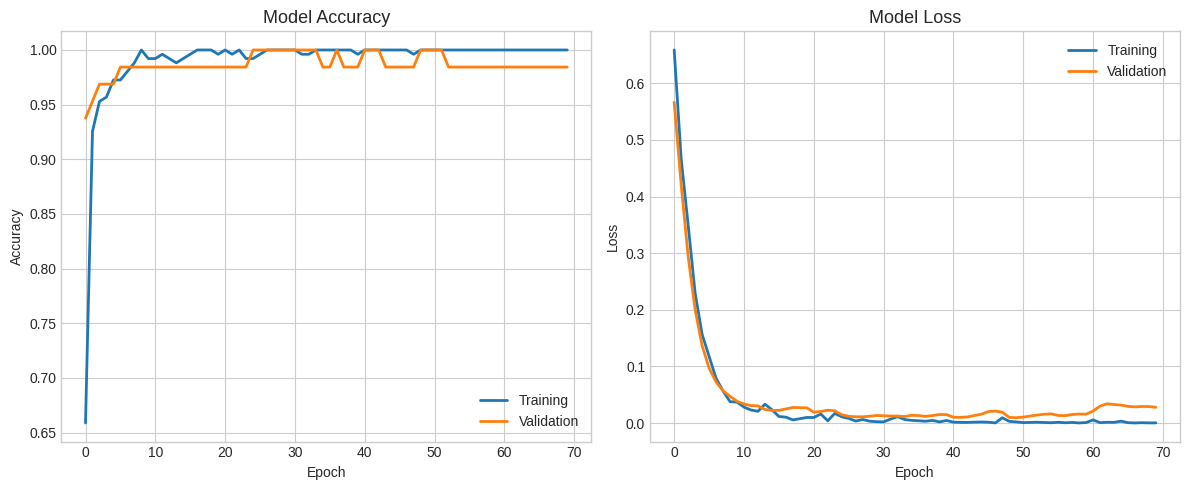

In [12]:
# ==========================================================
# Section 11 : Training History
# ==========================================================

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy
ax[0].plot(history.history["accuracy"], linewidth=2, label="Training")
ax[0].plot(history.history["val_accuracy"], linewidth=2, label="Validation")
ax[0].set_title("Model Accuracy", fontsize=13)
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy")
ax[0].legend()

# Loss
ax[1].plot(history.history["loss"], linewidth=2, label="Training")
ax[1].plot(history.history["val_loss"], linewidth=2, label="Validation")
ax[1].set_title("Model Loss", fontsize=13)
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].legend()

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "DNN_Training_History.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# ==========================================================
# Section 12 : Test Prediction
# ==========================================================

y_prob = model.predict(X_test, verbose=0)

y_pred = (y_prob >= 0.5).astype(int)

y_pred = y_pred.flatten()
y_prob = y_prob.flatten()

print("Prediction Completed.")

Prediction Completed.


In [14]:
# ==========================================================
# Section 13 : Performance Evaluation
# ==========================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("=" * 50)
print("Deep Neural Network Performance")
print("=" * 50)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

Deep Neural Network Performance
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000
ROC-AUC  : 1.0000

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        30

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



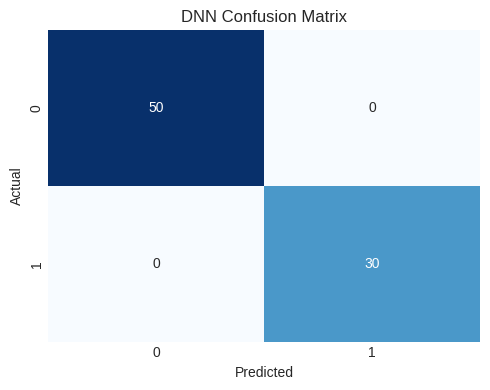

In [15]:
# ==========================================================
# Section 14 : Confusion Matrix
# ==========================================================

import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False
)

plt.title("DNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "DNN_Confusion_Matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

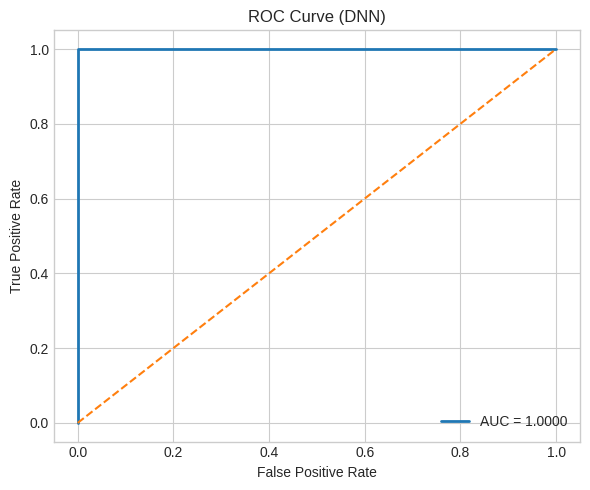

In [16]:
# ==========================================================
# Section 15 : ROC Curve
# ==========================================================

fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1], [0,1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve (DNN)")

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "DNN_ROC_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# ==========================================================
# Section 16 : Save Trained DNN Model
# ==========================================================

MODEL_PATH = os.path.join(MODEL_DIR, "Best_DNN_Model.keras")

model.save(MODEL_PATH)

print(f"DNN Model Saved Successfully:\n{MODEL_PATH}")

DNN Model Saved Successfully:
/content/drive/MyDrive/CKD Research Project/Saved_Models/Best_DNN_Model.keras


In [18]:
# ==========================================================
# Section 17 : Save Performance Metrics
# ==========================================================

performance_df = pd.DataFrame({
    "Model": ["Deep Neural Network"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

performance_path = os.path.join(
    RESULT_DIR,
    "DNN_Performance.csv"
)

performance_df.to_csv(
    performance_path,
    index=False
)

performance_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Deep Neural Network,1.0,1.0,1.0,1.0,1.0


In [19]:
# ==========================================================
# Section 18 : Save Training History
# ==========================================================

history_df = pd.DataFrame(history.history)

history_path = os.path.join(
    RESULT_DIR,
    "DNN_Training_History.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

history_df.head()

,accuracy,loss,val_accuracy,val_loss
0,0.658824,0.658718,0.937500,0.566446
1,0.925490,0.466600,0.953125,0.420930
2,0.952941,0.349737,0.968750,0.294227
3,0.956863,0.229628,0.968750,0.200321
4,0.972549,0.156713,0.968750,0.136754


In [20]:
# ==========================================================
# Section 19 : Final Summary
# ==========================================================

print("=" * 60)
print("Deep Learning (DNN) Pipeline Completed Successfully")
print("=" * 60)

print(f"Dataset Shape        : {df.shape}")
print(f"Training Samples     : {X_train.shape[0]}")
print(f"Testing Samples      : {X_test.shape[0]}")

print("\nPerformance Metrics")
print("-" * 60)

print(f"Accuracy             : {accuracy:.4f}")
print(f"Precision            : {precision:.4f}")
print(f"Recall               : {recall:.4f}")
print(f"F1-Score             : {f1:.4f}")
print(f"ROC-AUC              : {roc_auc:.4f}")

print("\nSaved Files")
print("-" * 60)

print(f"Model               : {MODEL_PATH}")
print(f"Performance CSV     : {performance_path}")
print(f"Training History    : {history_path}")

print("\nSaved Figures")
print("-" * 60)

print("DNN_Training_History.png")
print("DNN_Confusion_Matrix.png")
print("DNN_ROC_Curve.png")

print("\nNotebook 04 Completed Successfully.")

Deep Learning (DNN) Pipeline Completed Successfully
Dataset Shape        : (399, 25)
Training Samples     : 319
Testing Samples      : 80

Performance Metrics
------------------------------------------------------------
Accuracy             : 1.0000
Precision            : 1.0000
Recall               : 1.0000
F1-Score             : 1.0000
ROC-AUC              : 1.0000

Saved Files
------------------------------------------------------------
Model               : /content/drive/MyDrive/CKD Research Project/Saved_Models/Best_DNN_Model.keras
Performance CSV     : /content/drive/MyDrive/CKD Research Project/Results/DNN_Performance.csv
Training History    : /content/drive/MyDrive/CKD Research Project/Results/DNN_Training_History.csv

Saved Figures
------------------------------------------------------------
DNN_Training_History.png
DNN_Confusion_Matrix.png
DNN_ROC_Curve.png

Notebook 04 Completed Successfully.
